<a href="https://colab.research.google.com/github/Angelinat3/Machine-Learning2026/blob/main/JS09/JS09_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
!pip install annoy

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import time

from annoy import AnnoyIndex

In [21]:
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100

query = X[np.random.randint(0, n_points)]

In [22]:
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances) [:3]
time_exact = time.time() - start

print("Exact NN index:" , idx_exact)
print("Exact NN distances:", distances[idx_exact])
print("Exact Time:", round(time_exact*1000,4),"ms")

Exact NN index: [219 898 593]
Exact NN distances: [0.         1.36915938 2.27931544]
Exact Time: 1.2369 ms


In [23]:
f = 2
t = AnnoyIndex(f, 'euclidean')

for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)
time_ann = time.time() - start

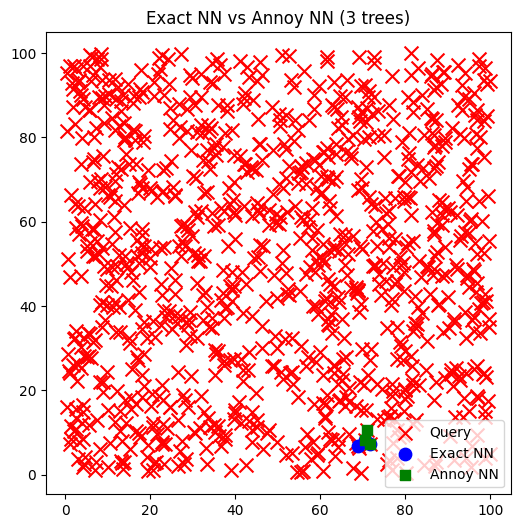

In [25]:
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c="red", marker="x", s=100, label="Query")

plt.scatter(X[idx_exact,0],X[idx_exact,1], c="blue", s=80, label="Exact NN")

plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()